# Message Intelligence System

## Part-A: Probability & Conceptual Foundation (Theory)

**Q1. What is Conditional Probability?**

**Ans:** Conditional probability is the probability of event A happening given that event B has already happened: P(A|B) = P(A and B) / P(B). Example: P(Spam | message has a URL).

**Q2. Explain Bayes' Theorem and its importance in classification problems.**

**Ans:** Bayes' Theorem is P(A|B) = P(B|A) x P(A) / P(B). It updates a prior belief using new evidence. In classification, P(Class|Features) = P(Features|Class) x P(Class) / P(Features), and the class with the highest posterior is predicted. It is the foundation of Naive Bayes.

**Q3. What assumptions does the Naive Bayes Classifier make?**

**Ans:** (1) Features are conditionally independent given the class. (2) Every feature contributes equally and independently. (3) In Gaussian Naive Bayes, numeric features follow a normal distribution within each class. It is called naive because real features are often correlated.

**Q4. Explain the working principle of KNN and SVM.**

**KNN:** Stores the training data. For a new message it finds the K nearest points using a distance metric and assigns the majority class. Features must be scaled.

**SVM:** Finds the hyperplane that separates the classes with the maximum margin. The closest points to the boundary are the support vectors. Kernels (RBF, polynomial) give non-linear boundaries.

**Q5. Compare distance-based, probabilistic, and margin-based classifiers.**

**Distance-based (KNN):** classifies by closeness to neighbours. Simple, but sensitive to scaling and slow on large data.

**Probabilistic (Naive Bayes):** classifies by the highest class probability. Fast and gives probabilities, but relies on the independence assumption.

**Margin-based (SVM):** classifies using the maximum-margin boundary. Strong on well-separated classes, but slower to train and harder to interpret.

## Part-B: Dataset Understanding & Preparation

**Step 1 - Load the dataset**

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel('..\data\Message_Intelligence_Dataset_5200.xlsx')
df.head()

<>:6: SyntaxWarning: invalid escape sequence '\d'
<>:6: SyntaxWarning: invalid escape sequence '\d'
C:\Users\OM\AppData\Local\Temp\ipykernel_25516\3295309693.py:6: SyntaxWarning: invalid escape sequence '\d'
  df = pd.read_excel('..\data\Message_Intelligence_Dataset_5200.xlsx')


,message_id,message_text,message_length,word_count,num_urls,num_digits,num_special_chars,spam_keyword_score,legit_keyword_score,sender_activity_score,sender_account_age_days,messages_sent_last_24h,timestamp,hour_of_day,day_of_week,spam_label
0,900001,Please find the attached invoice for the updat...,99,11,1,4,0,0,1,56.6,500.0,6.0,2025-11-24 02:00:00,2,0,0
1,900002,Let's catch up tomorrow regarding the timeline...,73,12,0,0,0,0,0,16.6,207.0,0.0,2025-12-17 21:00:00,21,2,0
2,900003,Can you send the report by end of day? next Mo...,67,13,0,0,0,0,1,25.7,418.0,6.0,2025-11-15 13:00:00,13,5,0
3,900004,Can you send the report by end of day? 10:30 A...,64,13,0,4,0,0,1,48.8,276.0,5.0,2025-12-17 23:00:00,23,2,0
4,900005,Could you review the document and share feedba...,84,14,0,0,0,0,1,33.0,683.0,7.0,2025-11-29 11:00:00,11,5,0


**Step 2 - Dataset information**

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5200 entries, 0 to 5199
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   message_id               5200 non-null   int64         
 1   message_text             5200 non-null   object        
 2   message_length           5200 non-null   int64         
 3   word_count               5200 non-null   int64         
 4   num_urls                 5200 non-null   int64         
 5   num_digits               5200 non-null   int64         
 6   num_special_chars        5200 non-null   int64         
 7   spam_keyword_score       5200 non-null   int64         
 8   legit_keyword_score      5200 non-null   int64         
 9   sender_activity_score    5094 non-null   float64       
 10  sender_account_age_days  5087 non-null   float64       
 11  messages_sent_last_24h   5038 non-null   float64       
 12  timestamp                5200 non-

**Step 3 - Missing values**

In [4]:
missing = df.isnull().sum()
missing[missing > 0]

sender_activity_score      106
sender_account_age_days    113
messages_sent_last_24h     162
dtype: int64

**Interpretation:** Only three sender-related columns have missing values: `sender_activity_score` (106), `sender_account_age_days` (113) and `messages_sent_last_24h` (162). All other columns are complete. These gaps are filled with the median in Step 8.

**Step 4 - Class distribution of the target**

spam_label
0    4227
1     973
Name: count, dtype: int64
spam_label
0    0.813
1    0.187
Name: proportion, dtype: float64


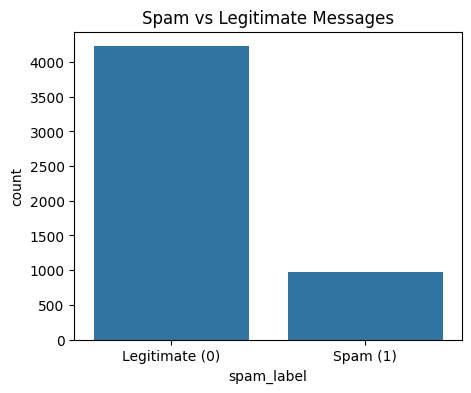

In [5]:
print(df['spam_label'].value_counts())
print(df['spam_label'].value_counts(normalize=True).round(3))

plt.figure(figsize=(5, 4))
sns.countplot(x='spam_label', data=df)
plt.xticks([0, 1], ['Legitimate (0)', 'Spam (1)'])
plt.title('Spam vs Legitimate Messages')
plt.show()

**Interpretation:** 4,227 messages (81.3%) are legitimate and 973 (18.7%) are spam. The imbalance is mild, so accuracy is not misleading here, but precision and recall are still tracked for the spam class.

**Step 5 - Feature correlation**

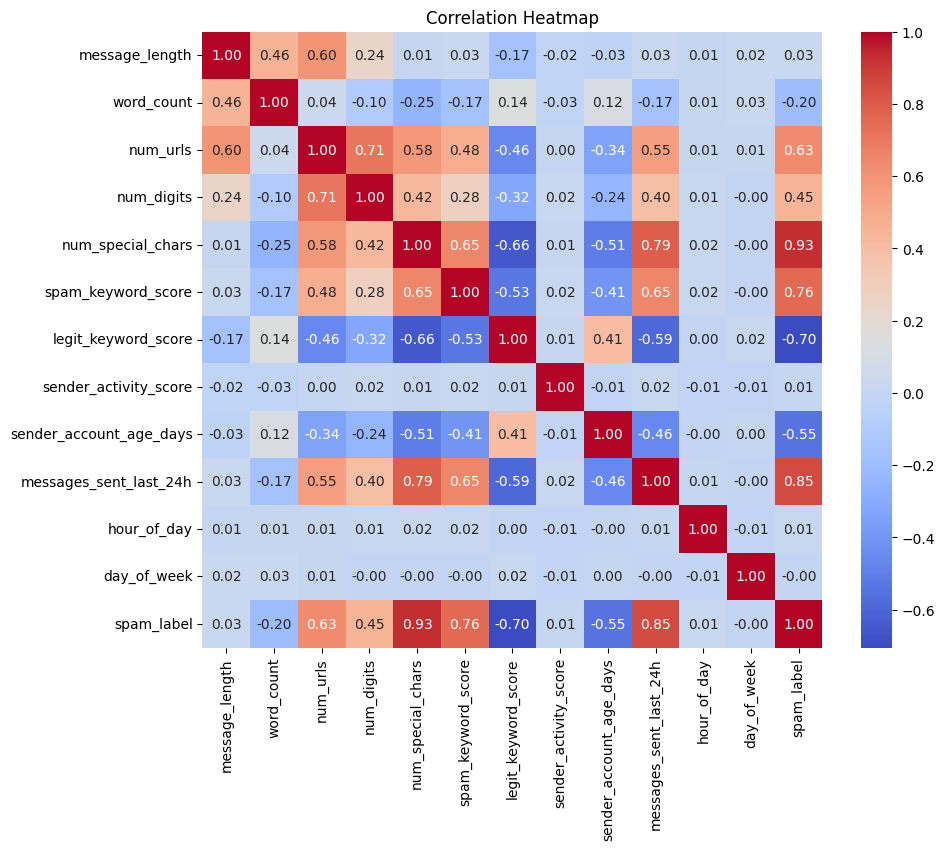

In [6]:
corr = df.drop(columns=['message_id', 'message_text', 'timestamp']).corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

**Interpretation:** `num_special_chars` (0.93), `messages_sent_last_24h` (0.85) and `spam_keyword_score` (0.76) have the strongest positive link with spam, while `legit_keyword_score` (-0.71) and `sender_account_age_days` (-0.55) point towards legitimate messages. `hour_of_day`, `day_of_week`, `sender_activity_score` and `message_length` are almost uncorrelated with the label. Several spam-signal features are also correlated with each other (up to about 0.8), which matters for the Naive Bayes independence assumption.

**Step 5b - Can a single feature separate the classes?**

In [7]:
pd.crosstab(df['spam_label'], df['num_special_chars'] >= 1,
            rownames=['Spam Label'], colnames=['Has special characters'])

Has special characters,False,True
Spam Label,,
0,4227,0
1,0,973


**Interpretation:** All 973 spam messages contain at least one special character and none of the 4,227 legitimate messages does. This single feature separates the two classes perfectly, so every model is expected to score very high on this dataset. The comparison in Part-F shows this.

**Step 6 - Identify input features and target variable**

`message_id` is only an identifier, `message_text` is raw text (its numerical summaries are already in the dataset) and `timestamp` is already captured by `hour_of_day` and `day_of_week`, so these three are left out.

In [8]:
NUM = ['message_length', 'word_count', 'num_urls', 'num_digits', 'num_special_chars',
       'spam_keyword_score', 'legit_keyword_score', 'sender_activity_score',
       'sender_account_age_days', 'messages_sent_last_24h', 'hour_of_day', 'day_of_week']
TARGET = 'spam_label'

X = df[NUM]
y = df[TARGET]
X.shape, y.shape

((5200, 12), (5200,))

**Step 7 - Train-test split**

Stratified, so both sets keep the same spam ratio.

In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True).round(3).to_dict())
print(y_test.value_counts(normalize=True).round(3).to_dict())

(4160, 12) (1040, 12)
{0: 0.813, 1: 0.187}
{0: 0.812, 1: 0.188}


**Step 8 - Preprocessing (imputation + scaling)**

Missing sender values are filled with the median, then features are standardised. The scaler is fitted on the training set only.

In [10]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

pre = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

X_train_p = pre.fit_transform(X_train)
X_test_p = pre.transform(X_test)

print(X_train_p.shape, X_test_p.shape)
print('Missing before:', X_train.isnull().sum().sum(), '| after:', np.isnan(X_train_p).sum())

(4160, 12) (1040, 12)
Missing before: 305 | after: 0


**Interpretation:** The 305 missing values in the training features were filled with medians, leaving none. Scaling is required for KNN (distance-based) and SVM (margin-based); Naive Bayes does not need it but is not harmed by it. The imputer and scaler are fitted on the training set only, so no test information leaks in.

## Part-C: Baseline Model - K-Nearest Neighbors

In [11]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

def evaluate(y_true, y_pred):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1-Score': f1_score(y_true, y_pred)
    }

**Step 1 - Baseline KNN (K = 5)**

In [12]:
knn_base = KNeighborsClassifier(n_neighbors=5)
knn_base.fit(X_train_p, y_train)
knn_base_pred = knn_base.predict(X_test_p)
evaluate(y_test, knn_base_pred)

{'Accuracy': 1.0, 'Precision': 1.0, 'Recall': 1.0, 'F1-Score': 1.0}

**Step 2 - Experiment with different values of K**

Each K is scored with 5-fold cross-validation on the training set (F1-Score), so the test set stays untouched.

Best K: 1 | CV F1: 1.0


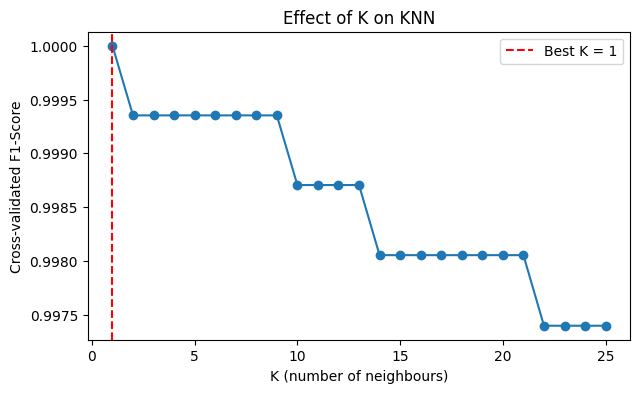

In [13]:
k_values = list(range(1, 26))
cv_f1 = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    score = cross_val_score(knn, X_train_p, y_train, cv=5, scoring='f1').mean()
    cv_f1.append(score)

best_k = k_values[int(np.argmax(cv_f1))]
print('Best K:', best_k, '| CV F1:', round(max(cv_f1), 4))

plt.figure(figsize=(7, 4))
plt.plot(k_values, cv_f1, marker='o')
plt.axvline(best_k, color='red', linestyle='--', label=f'Best K = {best_k}')
plt.xlabel('K (number of neighbours)')
plt.ylabel('Cross-validated F1-Score')
plt.title('Effect of K on KNN')
plt.legend()
plt.show()

**Interpretation:** Cross-validated F1 is highest at K = 1 (1.000) and slowly falls to about 0.997 at K = 25. The y-axis is zoomed in, so the total drop is under 0.3%. A small K follows the nearest neighbours closely, while a larger K averages over more neighbours and starts mixing in points of the other class near the boundary.

**Step 3 - How distance metrics affect predictions**

In [14]:
metrics = ['euclidean', 'manhattan', 'chebyshev', 'cosine']
rows = []

for m in metrics:
    knn = KNeighborsClassifier(n_neighbors=best_k, metric=m)
    cv_score = cross_val_score(knn, X_train_p, y_train, cv=5, scoring='f1').mean()
    knn.fit(X_train_p, y_train)
    scores = evaluate(y_test, knn.predict(X_test_p))
    rows.append([m, cv_score, scores['Accuracy'], scores['Precision'], scores['Recall'], scores['F1-Score']])

metric_df = pd.DataFrame(rows, columns=['Metric', 'CV F1', 'Test Accuracy', 'Test Precision', 'Test Recall', 'Test F1'])
metric_df.set_index('Metric').round(4)

,CV F1,Test Accuracy,Test Precision,Test Recall,Test F1
Metric,,,,,
euclidean,1.0000,1.000,1.0,1.0000,1.0000
manhattan,1.0000,1.000,1.0,1.0000,1.0000
chebyshev,0.9994,0.999,1.0,0.9949,0.9974
cosine,1.0000,1.000,1.0,1.0000,1.0000


**Interpretation:** Euclidean, Manhattan and Cosine all reach a perfect CV F1 and perfect test scores. Chebyshev is slightly weaker (test recall 0.9949, so 1 spam message is missed) because it looks only at the single largest feature difference and ignores the rest. Euclidean is kept because it is the first of the tied best metrics.

**Step 4 - Final KNN model**

Best K and best distance metric are chosen by cross-validation F1.

In [15]:
best_metric = metric_df.loc[metric_df['CV F1'].idxmax(), 'Metric']
print('Best K:', best_k, '| Best metric:', best_metric)

knn = KNeighborsClassifier(n_neighbors=best_k, metric=best_metric)
knn.fit(X_train_p, y_train)
knn_pred = knn.predict(X_test_p)

print(classification_report(y_test, knn_pred, target_names=['Legitimate', 'Spam']))
print(confusion_matrix(y_test, knn_pred))

Best K: 1 | Best metric: euclidean
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00       845
        Spam       1.00      1.00      1.00       195

    accuracy                           1.00      1040
   macro avg       1.00      1.00      1.00      1040
weighted avg       1.00      1.00      1.00      1040

[[845   0]
 [  0 195]]


**Interpretation:** KNN (K = 1, Euclidean) classifies all 1,040 test messages correctly: 845 legitimate and 195 spam, with no false positives and no false negatives.

**Step 5 - Messages that KNN misclassifies**

In [16]:
pd.set_option('display.max_colwidth', 100)

wrong = knn_pred != y_test.values
mis = df.loc[y_test.index[wrong], ['message_text', 'spam_label']].copy()
mis['predicted'] = knn_pred[wrong]

print('Misclassified messages:', wrong.sum(), 'out of', len(y_test))
mis.head(10)

Misclassified messages: 0 out of 1040


,message_text,spam_label,predicted


**Interpretation:** No message is misclassified, so the table is empty. KNN would be most likely to fail on spam that looks legitimate, such as the 228 spam messages in the data with a spam keyword score of 0. Here the other features (special characters, messages sent in 24 hours, account age) still separate them.

## Part-D: Support Vector Machine Classifier

**Step 1 - Linear, Polynomial and RBF kernels**

Kernel is compared with 5-fold cross-validation F1 on the training set; test scores are shown for reference.

In [17]:
from sklearn.svm import SVC

kernels = ['linear', 'poly', 'rbf']
rows = []

for kern in kernels:
    model = SVC(kernel=kern)
    cv_score = cross_val_score(model, X_train_p, y_train, cv=5, scoring='f1').mean()
    model.fit(X_train_p, y_train)
    scores = evaluate(y_test, model.predict(X_test_p))
    rows.append([kern, cv_score, scores['Accuracy'], scores['Precision'], scores['Recall'], scores['F1-Score']])

kernel_df = pd.DataFrame(rows, columns=['Kernel', 'CV F1', 'Test Accuracy', 'Test Precision', 'Test Recall', 'Test F1'])
kernel_df.set_index('Kernel').round(4)

,CV F1,Test Accuracy,Test Precision,Test Recall,Test F1
Kernel,,,,,
linear,1.0000,1.0,1.0,1.0,1.0
poly,0.9994,1.0,1.0,1.0,1.0
rbf,1.0000,1.0,1.0,1.0,1.0


**Interpretation:** All three kernels score 1.0 on the test set. Linear and RBF reach a CV F1 of 1.0000 and polynomial 0.9994. A linear kernel is enough because the data is already almost linearly separable, so the extra flexibility of the polynomial and RBF kernels adds nothing. Linear is kept as the first of the tied best kernels.

**Step 2 - Final SVM model**

In [18]:
best_kernel = kernel_df.loc[kernel_df['CV F1'].idxmax(), 'Kernel']
print('Best kernel:', best_kernel)

svm = SVC(kernel=best_kernel, probability=True, random_state=42)
svm.fit(X_train_p, y_train)
svm_pred = svm.predict(X_test_p)

print(classification_report(y_test, svm_pred, target_names=['Legitimate', 'Spam']))
print(confusion_matrix(y_test, svm_pred))

Best kernel: linear
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00       845
        Spam       1.00      1.00      1.00       195

    accuracy                           1.00      1040
   macro avg       1.00      1.00      1.00      1040
weighted avg       1.00      1.00      1.00      1040

[[845   0]
 [  0 195]]


c:\Users\OM\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


**Interpretation:** The linear SVM classifies all 1,040 test messages correctly (845 legitimate, 195 spam), with zero errors.

**Step 3 - Margin and support vectors**

In [19]:
svm_linear = SVC(kernel='linear')
svm_linear.fit(X_train_p, y_train)

margin_width = 2 / np.linalg.norm(svm_linear.coef_)
print('Linear SVM margin width:', round(margin_width, 4))
print('Linear SVM support vectors per class:', svm_linear.n_support_, '| total:', svm_linear.n_support_.sum(),
      '(', round(svm_linear.n_support_.sum() / len(X_train_p) * 100, 1), '% of training data )')
print('Final SVM (', best_kernel, ') support vectors per class:', svm.n_support_, '| total:', svm.n_support_.sum(),
      '(', round(svm.n_support_.sum() / len(X_train_p) * 100, 1), '% of training data )')

Linear SVM margin width: 1.8913
Linear SVM support vectors per class: [5 5] | total: 10 ( 0.2 % of training data )
Final SVM ( linear ) support vectors per class: [5 5] | total: 10 ( 0.2 % of training data )


**Interpretation:** In the 12-feature scaled space the linear SVM has a margin width of 1.89 and only 10 support vectors (5 per class, 0.2% of the 4,160 training messages) define the boundary. A wide margin held by so few support vectors shows the two classes are far apart.

**Step 4 - Visualise the margin on two features**

A linear SVM is drawn on two continuous features (scaled) to show the boundary, the margins and the support vectors.

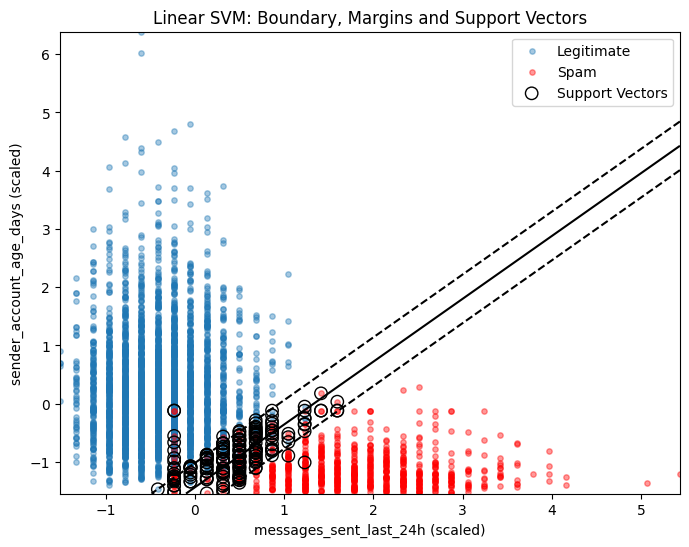

In [20]:
cols = [NUM.index('messages_sent_last_24h'), NUM.index('sender_account_age_days')]
X2 = X_train_p[:, cols]
y2 = y_train.values

svm2 = SVC(kernel='linear')
svm2.fit(X2, y2)

plt.figure(figsize=(8, 6))
plt.scatter(X2[y2 == 0, 0], X2[y2 == 0, 1], alpha=0.4, s=15, label='Legitimate')
plt.scatter(X2[y2 == 1, 0], X2[y2 == 1, 1], alpha=0.4, s=15, color='red', label='Spam')

xx, yy = np.meshgrid(np.linspace(X2[:, 0].min(), X2[:, 0].max(), 200),
                     np.linspace(X2[:, 1].min(), X2[:, 1].max(), 200))
zz = svm2.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
plt.contour(xx, yy, zz, levels=[-1, 0, 1], colors='black', linestyles=['--', '-', '--'])
plt.scatter(svm2.support_vectors_[:, 0], svm2.support_vectors_[:, 1], s=80, facecolors='none', edgecolors='black', label='Support Vectors')

plt.xlabel('messages_sent_last_24h (scaled)')
plt.ylabel('sender_account_age_days (scaled)')
plt.title('Linear SVM: Boundary, Margins and Support Vectors')
plt.legend()
plt.show()

**Interpretation:** The solid line is the decision boundary, the dashed lines are the margins and the circled points are the support vectors. With only these two features the classes overlap near the boundary, so many support vectors are needed; points far from the margin do not affect the boundary at all. With all 12 features the margin is much cleaner, as the 10 support vectors above show.

**Step 5 - SVM vs KNN**

In [21]:
svm_knn_df = pd.DataFrame({'KNN': evaluate(y_test, knn_pred), 'SVM': evaluate(y_test, svm_pred)}).T
svm_knn_df.round(4)

,Accuracy,Precision,Recall,F1-Score
KNN,1.0,1.0,1.0,1.0
SVM,1.0,1.0,1.0,1.0


**Interpretation:** Both models reach 1.0 on accuracy, precision, recall and F1. SVM stores only 10 support vectors, while KNN must keep all 4,160 training messages and compare every new message with them, so SVM is lighter at prediction time.

## Part-E: Naive Bayes Classifier & Probability

**Step 1 - Gaussian Naive Bayes**

In [22]:
from sklearn.naive_bayes import GaussianNB

nb = GaussianNB()
nb.fit(X_train_p, y_train)
nb_pred = nb.predict(X_test_p)

print(classification_report(y_test, nb_pred, target_names=['Legitimate', 'Spam']))
print(confusion_matrix(y_test, nb_pred))

              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00       845
        Spam       1.00      1.00      1.00       195

    accuracy                           1.00      1040
   macro avg       1.00      1.00      1.00      1040
weighted avg       1.00      1.00      1.00      1040

[[845   0]
 [  0 195]]


**Interpretation:** Naive Bayes also classifies all 1,040 test messages correctly (845 legitimate, 195 spam), even though the independence assumption is violated by the correlated features.

**Step 2 - Conditional probabilities computed manually**

P(Spam | B) is calculated in two ways on the training data: directly by counting, and with Bayes' Theorem: P(Spam | B) = P(B | Spam) x P(Spam) / P(B).

In [23]:
train_df = X_train.copy()
train_df['spam_label'] = y_train

p_spam = (train_df['spam_label'] == 1).mean()
print('P(Spam) =', round(p_spam, 4))

events = {
    'num_urls >= 1': train_df['num_urls'] >= 1,
    'num_special_chars >= 1': train_df['num_special_chars'] >= 1,
    'spam_keyword_score >= 1': train_df['spam_keyword_score'] >= 1
}

rows = []
for name, event in events.items():
    p_b = event.mean()
    p_b_given_spam = event[train_df['spam_label'] == 1].mean()
    direct = train_df[event]['spam_label'].mean()
    bayes = p_b_given_spam * p_spam / p_b
    rows.append([name, p_b, p_b_given_spam, direct, bayes])

cond_df = pd.DataFrame(rows, columns=['Event B', 'P(B)', 'P(B|Spam)', 'P(Spam|B) direct', 'P(Spam|B) Bayes'])
cond_df.set_index('Event B').round(4)

P(Spam) = 0.187


,P(B),P(B|Spam),P(Spam|B) direct,P(Spam|B) Bayes
Event B,,,,
num_urls >= 1,0.2041,0.7442,0.682,0.682
num_special_chars >= 1,0.1870,1.0000,1.000,1.000
spam_keyword_score >= 1,0.1462,0.7815,1.000,1.000


**Interpretation:** The direct count and Bayes' Theorem give identical values for every event, which confirms the theorem. The prior is P(Spam) = 0.187. A message with a URL is spam with probability 0.682 (a URL alone is not decisive, because legitimate messages contain URLs too). A message with a special character or a spam keyword is spam with probability 1.0 in this data.

**Step 3 - Bayes' Theorem applied to sample messages**

For each class: posterior is proportional to prior x product of Gaussian likelihoods of all 12 features (computed in log form). The two values are then normalised so they add up to 1.

In [24]:
def manual_posterior(x):
    log_post = []
    for cls in range(2):
        log_prior = np.log(nb.class_prior_[cls])
        log_like = -0.5 * np.sum(np.log(2 * np.pi * nb.var_[cls]) + (x - nb.theta_[cls]) ** 2 / nb.var_[cls])
        log_post.append(log_prior + log_like)
    log_post = np.array(log_post)
    post = np.exp(log_post - log_post.max())
    return post / post.sum(), log_post

legit_idx = np.where(y_test.values == 0)[0][0]
spam_idx = np.where(y_test.values == 1)[0]
sample_idx = [legit_idx, spam_idx[0], spam_idx[1]]

print('Class priors  P(Legit), P(Spam):', nb.class_prior_.round(4))
post, log_post = manual_posterior(X_test_p[sample_idx[0]])
print('Sample 1 log(prior x likelihood) for Legit, Spam:', log_post.round(2))
print('Sample 1 normalised posterior  P(Legit), P(Spam):', post.round(6))

Class priors  P(Legit), P(Spam): [0.813 0.187]
Sample 1 log(prior x likelihood) for Legit, Spam: [ 7.33000000e+00 -1.60883224e+09]
Sample 1 normalised posterior  P(Legit), P(Spam): [1. 0.]


**Interpretation:** For the first (legitimate) message the Legit score is about +7.3 and the Spam score is about -1.6 billion in log scale, so the normalised posterior is P(Legit) = 1 and P(Spam) = 0. The Spam score is so extreme because some features have almost zero variance inside a class (no spam message has a legitimate keyword and no legitimate message has a special character), so a message that breaks that pattern gets a vanishing likelihood for the wrong class.

**Step 4 - Theory vs model predictions**

In [25]:
rows = []
for i in sample_idx:
    manual, _ = manual_posterior(X_test_p[i])
    model_prob = nb.predict_proba(X_test_p[i].reshape(1, -1))[0]
    rows.append([df.loc[y_test.index[i], 'message_text'][:60], y_test.values[i], manual[1], model_prob[1], nb.predict(X_test_p[i].reshape(1, -1))[0]])

bayes_df = pd.DataFrame(rows, columns=['Message', 'Actual', 'Manual P(Spam)', 'Model P(Spam)', 'Model Prediction'])
bayes_df

,Message,Actual,Manual P(Spam),Model P(Spam),Model Prediction
0,Your order has been shipped and will arrive by the updated p,0,0.0,0.0,0
1,Earn money from home instantly a brand new phone limited tim,1,1.0,1.0,1
2,Limited offer! Get exclusive bonus limited time! http://prom,1,1.0,1.0,1


**Interpretation:** The manual calculation (prior x Gaussian likelihoods, normalised) matches `predict_proba` exactly for all three messages: 0 for the legitimate message and 1 for both spam messages. The theory and the model agree, and the predictions match the actual labels.

## Part-F: Model Comparison & Evaluation

**Step 1 - Accuracy, Precision, Recall and F1-Score for all models**

In [26]:
models = {'KNN': knn, 'SVM': svm, 'Naive Bayes': nb}
rows = []

for name, model in models.items():
    pred = model.predict(X_test_p)
    scores = evaluate(y_test, pred)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append([name, scores['Accuracy'], scores['Precision'], scores['Recall'], scores['F1-Score'], fp, fn])

compare_df = pd.DataFrame(rows, columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score', 'False Positives', 'False Negatives'])
compare_df.set_index('Model').round(4)

,Accuracy,Precision,Recall,F1-Score,False Positives,False Negatives
Model,,,,,,
KNN,1.0,1.0,1.0,1.0,0,0
SVM,1.0,1.0,1.0,1.0,0,0
Naive Bayes,1.0,1.0,1.0,1.0,0,0


**Interpretation:** KNN, SVM and Naive Bayes all score 1.0 on accuracy, precision, recall and F1, with 0 false positives and 0 false negatives on the 1,040 test messages. On this dataset the test metrics cannot rank the models.

**Step 2 - Visual comparison**

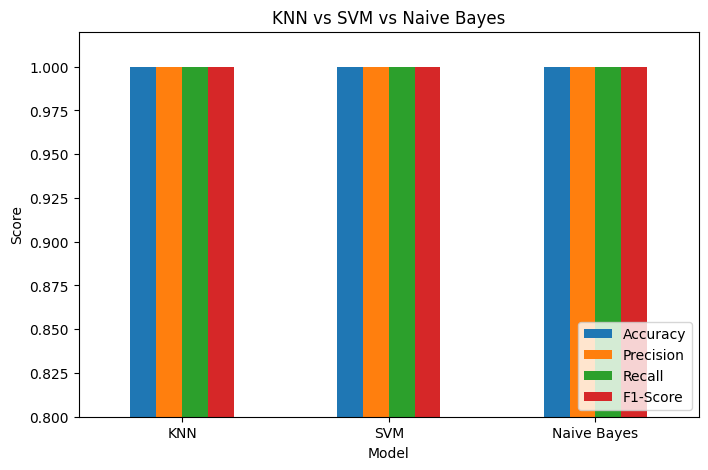

In [27]:
compare_df.set_index('Model')[['Accuracy', 'Precision', 'Recall', 'F1-Score']].plot(kind='bar', figsize=(8, 5))
plt.title('KNN vs SVM vs Naive Bayes')
plt.ylabel('Score')
plt.ylim(0.8, 1.02)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.show()

**Interpretation:** All bars sit at 1.0, so the three models are tied on every metric.

**Step 3 - Best model for high precision and for high recall**

In [28]:
for metric in ['Precision', 'Recall', 'F1-Score']:
    top = compare_df[compare_df[metric] == compare_df[metric].max()]['Model'].tolist()
    print(f'Best {metric}:', ', '.join(top))

Best Precision: KNN, SVM, Naive Bayes
Best Recall: KNN, SVM, Naive Bayes
Best F1-Score: KNN, SVM, Naive Bayes


**Interpretation:** All three models tie for the best precision, recall and F1-Score, so the final choice has to be made on practical grounds, explained in Part-G.

## Part-G: Final Analysis & Reporting

**Strengths and weaknesses**

- **KNN:** simple, no training step and flexible, but it stores all 4,160 messages, predicts slowly, needs scaling and K = 1 is sensitive to noise.
- **SVM (linear):** only 10 support vectors, a wide stable margin and smooth spam probabilities, but it needs scaling and is harder to explain than Naive Bayes.
- **Naive Bayes:** fastest to train and a tiny model (means and variances), but its independence assumption is broken by correlated features.

**Impact of the probability assumptions in Naive Bayes**

Special characters, messages sent in 24 hours and keyword scores are correlated (up to about 0.8), so the independence assumption does not hold. The predicted classes are still correct because every feature points to the same class, but the probabilities are overconfident (exactly 0 or 1) and should not be used as calibrated risk scores.

**Interpretability vs performance**

All three models are tied at 100%, so no performance has to be given up for interpretability. Naive Bayes (per-feature probabilities) and the linear SVM (feature weights) are the easiest to explain; KNN can only say that a message is similar to its neighbours.

**Dataset note**

`num_special_chars` alone separates spam from legitimate messages perfectly, so the 100% scores describe this dataset and not real-world spam, which is messier. The model should be re-tested on fresh messages before it is trusted.

**Business recommendation**

Deploy the **linear SVM**. It ties with the others on every metric, is the most compact (10 support vectors), has a stable linear boundary and gives smooth spam probabilities. Keep Naive Bayes as a fast baseline. A false positive blocks a genuine message and a false negative lets spam through, so both error counts should be monitored on live data.

**Export - final model (.pkl) and evaluation summary (.json)**

In [29]:
import pickle
import json
from pathlib import Path
from sklearn.metrics import roc_auc_score

final_name = 'SVM'
final_model = models[final_name]

final_pipeline = Pipeline([
    ('preprocessing', pre),
    ('model', final_model)
])

final_pred = final_pipeline.predict(X_test)
final_prob = final_pipeline.predict_proba(X_test)[:, 1]
print('Final model:', final_name)
print('Matches earlier predictions:', bool((final_pred == models[final_name].predict(X_test_p)).all()))
print(classification_report(y_test, final_pred, target_names=['Legitimate', 'Spam']))

Final model: SVM
Matches earlier predictions: True
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00       845
        Spam       1.00      1.00      1.00       195

    accuracy                           1.00      1040
   macro avg       1.00      1.00      1.00      1040
weighted avg       1.00      1.00      1.00      1040



In [30]:
Path('model').mkdir(exist_ok=True)

with open('model/message_intelligence_pipeline.pkl', 'wb') as file:
    pickle.dump(final_pipeline, file)

final_scores = evaluate(y_test, final_pred)
summary = {
    'model_name': final_name,
    'accuracy': round(final_scores['Accuracy'], 4),
    'precision': round(final_scores['Precision'], 4),
    'recall': round(final_scores['Recall'], 4),
    'f1_score': round(final_scores['F1-Score'], 4),
    'roc_auc': round(roc_auc_score(y_test, final_prob), 4),
    'confusion_matrix': confusion_matrix(y_test, final_pred).tolist(),
    'train_rows': int(len(X_train)),
    'test_rows': int(len(X_test)),
    'features': NUM,
    'target': TARGET,
    'labels': {'0': 'Legitimate', '1': 'Spam'},
    'model_comparison': compare_df.set_index('Model')[['Accuracy', 'Precision', 'Recall', 'F1-Score']].round(4).to_dict(orient='index')
}

with open('model/metrics.json', 'w') as file:
    json.dump(summary, file, indent=2)

print('Saved: model/message_intelligence_pipeline.pkl and model/metrics.json')

Saved: model/message_intelligence_pipeline.pkl and model/metrics.json


**Check - load the saved pipeline and predict new messages**

In [31]:
with open('model/message_intelligence_pipeline.pkl', 'rb') as file:
    loaded_pipeline = pickle.load(file)

samples = pd.DataFrame({
    'message_length': [60, 95],
    'word_count': [11, 9],
    'num_urls': [0, 1],
    'num_digits': [1, 6],
    'num_special_chars': [0, 2],
    'spam_keyword_score': [0, 3],
    'legit_keyword_score': [1, 0],
    'sender_activity_score': [55.0, 50.0],
    'sender_account_age_days': [400.0, 30.0],
    'messages_sent_last_24h': [5.0, 25.0],
    'hour_of_day': [11, 3],
    'day_of_week': [2, 5]
})

result = loaded_pipeline.predict(samples)
probability = loaded_pipeline.predict_proba(samples)[:, 1]

for i in range(len(samples)):
    label = 'Spam' if result[i] == 1 else 'Legitimate'
    print(f'Message {i + 1}: {label} (spam probability = {probability[i]:.3f})')

Message 1: Legitimate (spam probability = 0.000)
Message 2: Spam (spam probability = 1.000)
